# 코드 A · 고객 데이터 4종 둘러보기
**핀테크 데이터 분석 : 실제로 해보는 데이터 분석편 #01**  
원본: [fintech-data/Revolution](https://github.com/fintech-data/Revolution) `Loading_Data.ipynb` → 이 폴더의 `original_Loading_Data.ipynb`  
해설 페이지: https://adminmrobo.github.io/fintech_data_analysis/hands_on_01.html

> 코드를 몰라도 괜찮아요. 위에서부터 ▶ 실행 버튼만 차례로 누르면 됩니다.

## 이 코드가 하는 일
은행 고객 명부, 쇼핑몰 마케팅 명부, 건강보험료 표, 여행자보험 판매 장부 — **표 네 권을 차례로 펼쳐서 첫 장만 훑어보는** 코드입니다.

> 비유: 새 학기에 받은 반 명부 네 권을 책상에 펼쳐 놓고 "몇 명이지? 어떤 항목이 적혀 있지?"를 확인하는 일.

원본 노트북은 `original_Loading_Data.ipynb`에 그대로 있습니다. 이 노트북은 같은 일을 하면서 결과를 한 줄씩 설명합니다.

In [1]:
import os, io, urllib.request
import pandas as pd
pd.set_option('display.max_columns', 12); pd.set_option('display.width', 120)

# 데이터 위치: 이 폴더의 data/ 에 있으면 그걸 쓰고, 없으면(Colab 등) GitHub에서 바로 읽습니다.
RAW = 'https://raw.githubusercontent.com/adminmrobo/fintech_data_analysis/main/hands_on/01/A_customer_data_tour/data/'
def load(name, **kw):
    local = os.path.join('data', name)
    src = local if os.path.exists(local) else RAW + urllib.parse.quote(name)
    return pd.read_csv(src, low_memory=False, **kw)
print('준비 완료')

준비 완료


### ① 은행 고객 명부 (Bank_customers_data.csv)
고객 한 명이 한 줄(행)입니다. `Attrition_Flag`는 고객이 떠났는지(Attrited) 남았는지(Existing)를 적은 열이에요.

In [2]:
bank_customers = load('Bank_customers_data.csv')
bank_customers.head()

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,...,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,...,11914.0,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,...,7392.0,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,...,3418.0,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,...,796.0,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,...,4716.0,2.175,816,28,2.500,0.000


In [3]:
print('행(고객 수), 열(항목 수):', bank_customers.shape)
bank_customers['Attrition_Flag'].value_counts()

행(고객 수), 열(항목 수): (10127, 21)


Attrition_Flag
Existing Customer    8500
Attrited Customer    1627
Name: count, dtype: int64

In [4]:
# 떠난 고객과 남은 고객의 1년 거래 횟수 평균
bank_customers.groupby('Attrition_Flag')['Total_Trans_Ct'].mean().round(1)

Attrition_Flag
Attrited Customer    44.9
Existing Customer    68.7
Name: Total_Trans_Ct, dtype: float64

### ② 다이렉트 마케팅 명부 (DirectMarketing.csv)
쇼핑몰 고객 1,000명. 마지막 열 `AmountSpent`(1년 이용액)를 맞히는 데 쓰는 데이터입니다.

In [5]:
direct_marketing = load('DirectMarketing.csv')
direct_marketing.head()

,Age,Gender,OwnHome,Married,Location,Salary,Children,History,Mailing,AmountSpent
0,Old,Female,Own,Single,Far,47500,0,High,6,755
1,Middle,Male,Rent,Single,Close,63600,0,High,6,1318
2,Young,Female,Rent,Single,Close,13500,0,Low,18,296
3,Middle,Male,Own,Married,Close,85600,1,High,18,2436
4,Middle,Female,Own,Single,Close,68400,0,High,12,1304


In [6]:
# 빈 값(결측값) 세기 — History 열에 빈 값이 많아요
direct_marketing.isna().sum()

Age              0
Gender           0
OwnHome          0
Married          0
Location         0
Salary           0
Children         0
History        303
Mailing          0
AmountSpent      0
dtype: int64

### ③ 건강보험료 표 (insurance.csv)

In [7]:
insurance = load('insurance.csv')
print(insurance.shape)
insurance.groupby('smoker')['charges'].mean().round(0)

(1338, 7)


smoker
no      8434.0
yes    32050.0
Name: charges, dtype: float64

### ④ 여행자보험 판매 장부 (travel insurance.csv)

In [8]:
travel_insurance = load('travel insurance.csv')
print(travel_insurance.shape)
travel_insurance['Claim'].value_counts()

(63326, 11)


Claim
No     62399
Yes      927
Name: count, dtype: int64

In [9]:
# 이상한 값 찾기: 성별 빈 값 수, 가장 많은 나이, 음수 보험기간
print('Gender 빈 값:', travel_insurance['Gender'].isna().sum())
print('Age 최댓값:', travel_insurance['Age'].max(), '/ 118세 행 수:', (travel_insurance['Age'] >= 118).sum())
print('Duration이 음수인 행:', (travel_insurance['Duration'] < 0).sum())

Gender 빈 값: 45107
Age 최댓값: 118 / 118세 행 수: 984
Duration이 음수인 행: 5


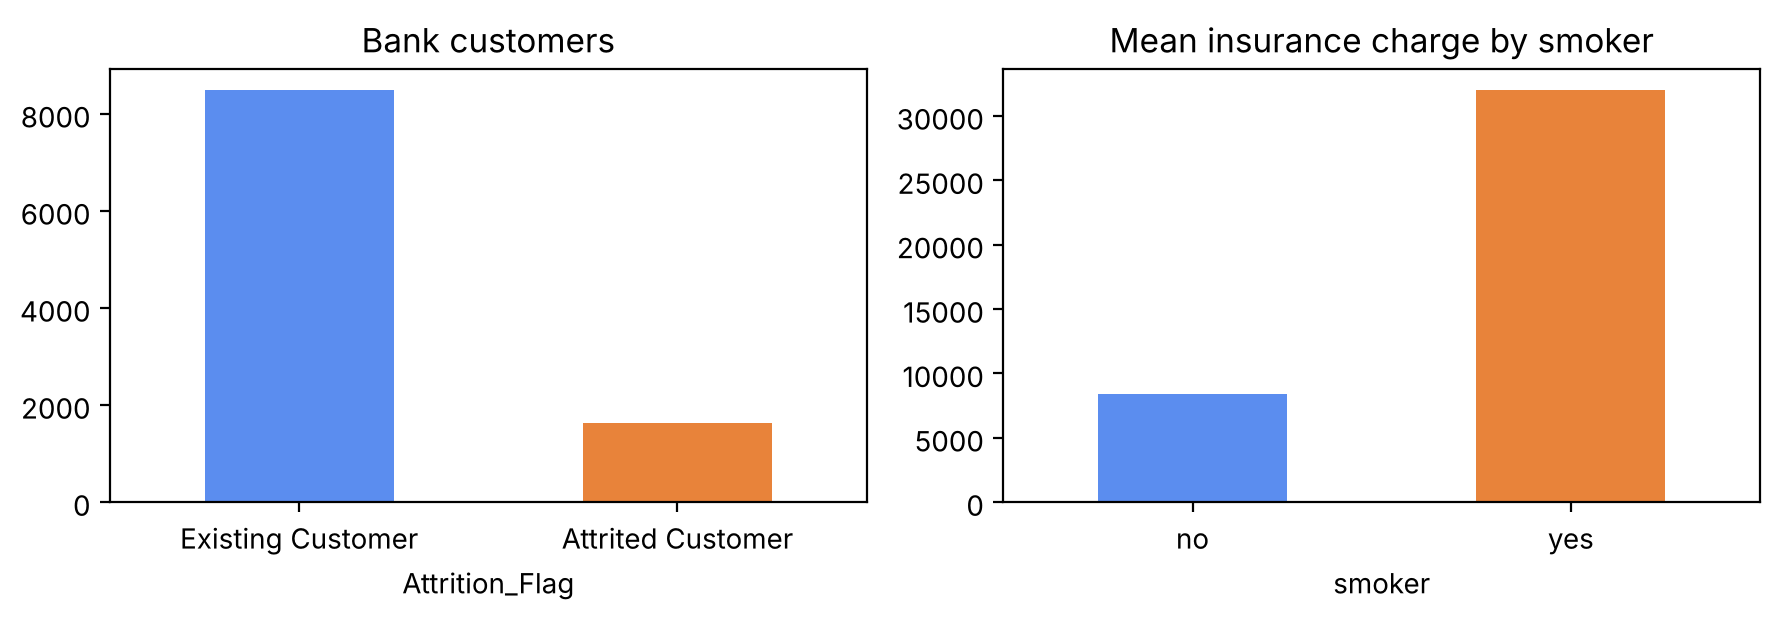

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
bank_customers['Attrition_Flag'].value_counts().plot.bar(ax=ax[0], color=['#5b8def', '#e8833a'], rot=0, title='Bank customers')
insurance.groupby('smoker')['charges'].mean().plot.bar(ax=ax[1], color=['#5b8def', '#e8833a'], rot=0, title='Mean insurance charge by smoker')
plt.tight_layout(); plt.show()